# 3.1 · Can constrained adaptation retain generality?

[Notebook index](../README.md) · [Experiment 2 results](<../2. Experiment 2/2.4_lgd_results.ipynb>)

Fix 50% credit / 50% generic synthetic data and compare four adaptation methods with the
full-CPT-with-decay baseline from Experiment 2. Two tasks, two backbones and three paired seeds
give **48 additional runs plus 12 reused baselines**, each with 1,000 optimizer updates.
The reused baseline always uses the predetermined primary rate: 2e-5 for TabICLv2 and 1e-5 for
TabPFN-3. Its score never determines whether it is reused.

All method settings are fixed before this benchmark. Report every method on credit and native OOD
at updates 125, 250, 500 and 1,000. Historical benchmark exposure remains disclosed; neither domain
selects a rate, adapter configuration or stopping point.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src" / "visualize").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from src.visualize import figures, style, continuation
from src.experiments import results
style.apply()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)
FIGS = figures.FigureSaver("3.1_retention")

## A · Registered interventions
No-decay CPT isolates weight decay. L2-SP anchors weights to the released checkpoint.
DiagScale learns final query scales. Rank-16 Q/V LoRA keeps keys and other backbone weights
frozen. These are multi-table adaptations of methods mostly studied in downstream fine-tuning,
not guaranteed improvements.

WindowsPath('C:/Users/U0152019/PhD Documents/Projects/4. CreditICL/CreditICL/output CreditICL/figures/3.1_retention/01_registered_retention_design.pdf')

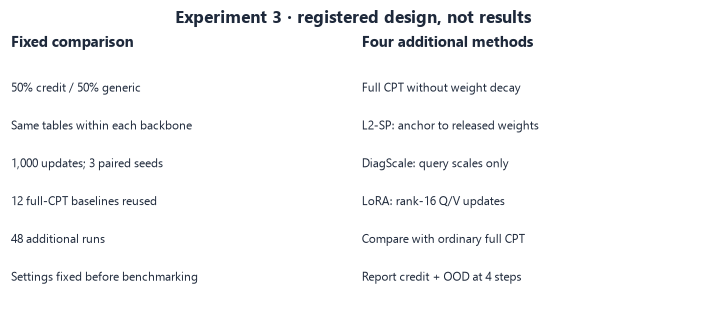

In [2]:
FIGS.save(continuation.design_figure(3), "registered_retention_design",
    caption="Registered retention comparison at a fixed 50% credit mixture: four additional methods across two backbones, two prediction tasks and three paired seeds give 48 runs. Twelve primary-rate full-CPT-with-decay baselines are reused from Experiment 2. All settings are fixed before benchmarking; four checkpoints end at the primary 1,000-update endpoint.")

## B · Fixed adaptation recipes
Full CPT without decay and L2-SP use the backbone's predetermined primary learning rate, with
zero weight decay. L2-SP anchors weights to the released checkpoint with alpha 0.003.
DiagScale learns final query scales at peak rate 0.03. Q/V LoRA uses rank 16, alpha 16 and peak
rate 1e-4. Both adapter methods use AdamW with weight decay 0.01 on trainable adapter parameters;
the backbone stays frozen. These are fixed research choices, not benchmark-selected optima.

The table records resolved settings. Method-specific learning rates and trainable parameter counts
differ, so the comparison evaluates complete adaptation recipes, not an isolated parameter-count effect.

In [3]:
print(continuation.retention_recipe().to_string(index=False))
print("Settings are fixed for both tasks; no benchmark scores or selection receipts choose them.")

Backbone             Method Peak LR  Weight decay  L2-SP alpha  Updates
TabICLv2 Full CPT, no decay   2e-05          0.00        0.000     1000
TabICLv2       L2-SP anchor   2e-05          0.00        0.003     1000
TabICLv2          DiagScale    0.03          0.01        0.000     1000
TabICLv2           Q/V LoRA  0.0001          0.01        0.000     1000
TabPFN-3 Full CPT, no decay   1e-05          0.00        0.000     1000
TabPFN-3       L2-SP anchor   1e-05          0.00        0.003     1000
TabPFN-3          DiagScale    0.03          0.01        0.000     1000
TabPFN-3           Q/V LoRA  0.0001          0.01        0.000     1000
Settings are fixed for both tasks; no benchmark scores or selection receipts choose them.


## C · Final credit benefit and OOD retention
Pair each method with the reused Experiment 2 baseline at its predetermined primary rate and the
same training seed. Average folds within datasets before uncertainty over datasets. Earlier benchmark
exposure remains disclosed. Trainable parameter counts and measured computational costs differ
between methods and remain part of the reported comparison.

In [4]:
for task in ("pd", "lgd"):
    for backbone in continuation.BACKBONES:
        if not results.benchmark_frames(task, 3, final_only=True).empty:
            FIGS.save(continuation.retention_effects(task, backbone), f"final_{task}_{backbone}",
                caption="Final credit-benchmark and native-OOD differences for four methods against their reused primary-rate full-CPT-with-decay baseline, paired by seed and dataset; intervals are descriptive nominal 95% paired-dataset bootstrap intervals.")

## D · Retention as adaptation proceeds
Four checkpoints describe credit/OOD trajectories. Keep 1,000 updates as the primary endpoint;
do not select an earlier step from these reporting curves. Loss, gradients, hardware and
parameter-drift logs remain available for diagnosis.

In [5]:
for task in ("pd", "lgd"):
    for backbone in continuation.BACKBONES:
        for metric in (("roc_auc", "log_loss", "brier") if task == "pd" else ("r2", "crps")):
            frames = results.benchmark_frames(task, 3)
            if not results.complete_scores(frames, metric, experiment=3).empty:
                FIGS.save(continuation.checkpoint_curves(task, backbone, experiment=3, metric=metric),
                    f"trajectory_{task}_{backbone}_{metric}",
                    caption="Credit-benchmark and native-OOD scores against optimizer updates (125, 250, 500 and 1,000) for four methods and the reused full-CPT baseline; each curve requires three complete seeds, with shading for their mean-score range.")

## Summary
A: interventions; B: fixed adaptation recipes; C: final contrasts; D: trajectories.

In [6]:
print(continuation.retention_summary())
print(FIGS.summary())

A · REGISTERED DESIGN
Fixed 50% mixture; 48 new 1,000-update runs plus 12 reused Exp2 controls.
B · FIXED ADAPTATION RECIPES
Backbone             Method Peak LR  Weight decay  L2-SP alpha  Updates
TabICLv2 Full CPT, no decay   2e-05          0.00        0.000     1000
TabICLv2       L2-SP anchor   2e-05          0.00        0.003     1000
TabICLv2          DiagScale    0.03          0.01        0.000     1000
TabICLv2           Q/V LoRA  0.0001          0.01        0.000     1000
TabPFN-3 Full CPT, no decay   1e-05          0.00        0.000     1000
TabPFN-3       L2-SP anchor   1e-05          0.00        0.003     1000
TabPFN-3          DiagScale    0.03          0.01        0.000     1000
TabPFN-3           Q/V LoRA  0.0001          0.01        0.000     1000
No benchmark-driven learning-rate or adapter selection.
C · CREDIT AND OOD RETENTION
Paired final contrasts use the same training seeds and five-fold assignments.
PD / TabICLv2 / credit: final paired results not complete
PD / T